# Skew-symmetric connectivity from a local learning rule

Reproduces Fig. 8 (Appendix J.4). The generators need not be hard-coded: a local,
biologically plausible rule driven by time-lagged antisymmetric correlations,

$$\Delta W_{ij} = \eta\big(r_i(t)r_j(t+\tau) - r_j(t)r_i(t+\tau)\big) - \alpha W_{ij}$$

drives $W$ toward the skew-symmetry Sec. 2.3 requires.

Splitting $W$ into $S = W + W^\top$ and $A = W - W^\top$ separates the dynamics. The
Hebbian term is antisymmetric by construction, so it contributes **nothing** to $S$:

$$\Delta S = -\alpha S \quad\Longrightarrow\quad S(t) = (1-\alpha)^t S(0)$$

while $A$ is driven by the correlations and stabilised by the decay, giving
$A^* = \tfrac{2\eta}{\alpha}\langle H\rangle_t$.

**Read the two panels differently.** The decay of $S$ is *algebra*, not evidence — it
holds for any input whatsoever, because the update term is exactly antisymmetric. The
first cell below checks it against the closed form rather than just watching it shrink.
The claim with content is the steady state, and that one depends on the input.

**So the input matters.** The original version of this notebook drove the rule with white
noise, where $\langle H\rangle \to 0$ as $1/\sqrt{T}$ and the rule learns only
fluctuation. Driving it instead with activity that is genuinely *being transported* by a
generator — $r(t{+}1) = e^{\delta t\,\Omega}r(t)$, the situation the framework describes —
gives $\langle H\rangle$ a non-zero limit, and $A$ converges to it. Both are shown.

Appendix J.4 states the limitation plainly, and the last cell reproduces it: the rule
yields *a* skew-symmetric matrix, not the **commuting pair** a coherent spatial map needs.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from expmap.plasticity import (
    antisymmetric_correlation,
    learn_connectivity,
    steady_state_antisymmetric,
    transported_activity,
)

# Fig. 8 parameters: a 32 x 32 weight matrix, alpha = 0.001, eta = 0.01, 5000 iterations.
N = 32
ETA = 0.01
ALPHA = 0.001
LAG = 1
T = 5000
SEED = 0

rng = np.random.default_rng(SEED)

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

In [2]:
# Fig. 8 as published: white-noise input, tracking both components.
noise_rates = rng.standard_normal((T + LAG, N)) * 0.5
W0 = rng.standard_normal((N, N)) * 0.1

W_noise, history = learn_connectivity(
    noise_rates, eta=ETA, alpha=ALPHA, lag=LAG, W0=W0, record=True
)

# The symmetric part should follow (1 - alpha)^t exactly, not approximately.
steps = np.arange(T)
closed_form = (1 - ALPHA) ** steps * np.sqrt(np.mean((W0 + W0.T) ** 2))
deviation = np.max(np.abs(history["symmetric_rms"] - closed_form))

print(f"symmetric RMS {history['symmetric_rms'][0]:.4f} -> {history['symmetric_rms'][-1]:.2e}")
print(f"max |S(t) - (1-alpha)^t S(0)| = {deviation:.2e}   (identity, so machine precision)")
print(f"antisymmetric RMS {history['antisymmetric_rms'][0]:.4f} -> {history['antisymmetric_rms'][-1]:.4f}")

symmetric RMS 0.1444 -> 9.71e-04
max |S(t) - (1-alpha)^t S(0)| = 6.94e-17   (identity, so machine precision)
antisymmetric RMS 0.1458 -> 0.1554


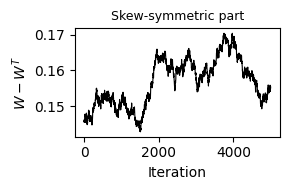

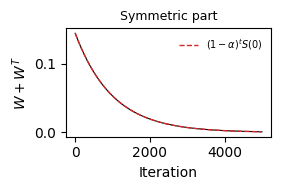

In [3]:
# Fig. 8: the skew part persists, the symmetric part vanishes.
for key, label, name in [
    ("antisymmetric_rms", r"$W - W^T$", "learning_rule_skew_symmetric"),
    ("symmetric_rms", r"$W + W^T$", "learning_rule_symmetric"),
]:
    plt.figure(figsize=(3, 2))
    plt.plot(steps, history[key], "k", linewidth=0.8)
    if key == "symmetric_rms":
        plt.plot(steps, closed_form, "C3--", linewidth=1, label=r"$(1-\alpha)^t S(0)$")
        plt.legend(fontsize=7, frameon=False)
    plt.ylabel(label)
    plt.xlabel("Iteration")
    plt.title("Skew-symmetric part" if key == "antisymmetric_rms" else "Symmetric part", fontsize=9)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"{name}.svg", dpi=300, bbox_inches="tight")
    plt.savefig(FIGURE_DIR / f"{name}.png", dpi=300, bbox_inches="tight")

  white noise : 0.0014 (T=1000) -> 0.0003 (T=16000)
  transported : 0.0010 (T=1000) -> 0.0009 (T=16000)

  white noise decays as 1/sqrt(T); transported activity converges to a limit,
  so the curves cross and the structured signal wins for long enough sequences


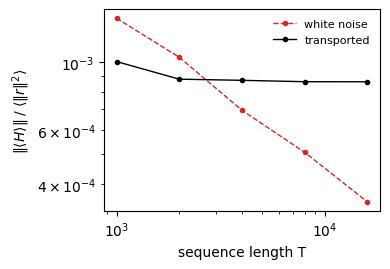

In [4]:
# What does the rule actually learn? Compare white noise against activity being
# transported by a known generator. <H> is what sets the steady state, so track how it
# behaves as the sequence gets longer.
A_true = rng.standard_normal((N, N))
OMEGA = (A_true - A_true.T) / np.sqrt(N)  # the generator carrying the structured activity

lengths = [1000, 2000, 4000, 8000, 16000]
correlation_scale = {"white noise": [], "transported": []}

for length in lengths:
    noise = rng.standard_normal((length + LAG, N)) * 0.5
    structured = transported_activity(OMEGA, n_steps=length + LAG, seed=SEED)
    for label, rates in [("white noise", noise), ("transported", structured)]:
        # Normalise by the mean squared activity: <H> scales with ||r||^2, and the two
        # inputs have different amplitudes, so the raw magnitudes are not comparable.
        magnitude = np.sqrt(np.mean(antisymmetric_correlation(rates, LAG) ** 2))
        correlation_scale[label].append(magnitude / np.mean(np.sum(rates**2, axis=1)))

plt.figure(figsize=(4, 2.8))
for label, style in [("white noise", "C3--o"), ("transported", "k-o")]:
    plt.loglog(lengths, correlation_scale[label], style, markersize=3, linewidth=1, label=label)
plt.xlabel("sequence length T")
plt.ylabel(r"$\|\langle H \rangle\| \;/\; \langle \|r\|^2 \rangle$")
plt.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "learning_rule_correlation_scaling.svg", dpi=300, bbox_inches="tight")

for label in correlation_scale:
    values = correlation_scale[label]
    print(f"  {label:12s}: {values[0]:.4f} (T={lengths[0]}) -> {values[-1]:.4f} (T={lengths[-1]})")
print("\n  white noise decays as 1/sqrt(T); transported activity converges to a limit,")
print("  so the curves cross and the structured signal wins for long enough sequences")

corr(A_learned, A*)     = 0.9565
corr for white noise    = 0.6625


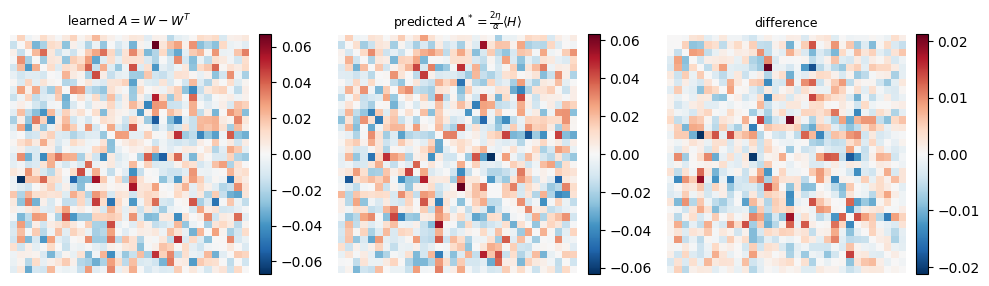

In [5]:
# The steady state A* = (2 eta / alpha) <H>, checked where <H> is a real signal.
structured = transported_activity(OMEGA, n_steps=T + LAG, seed=SEED)
W_structured, _ = learn_connectivity(structured, eta=ETA, alpha=ALPHA, lag=LAG, seed=SEED)

A_learned = W_structured - W_structured.T
A_predicted = steady_state_antisymmetric(structured, eta=ETA, alpha=ALPHA, lag=LAG)

print(f"corr(A_learned, A*)     = {np.corrcoef(A_learned.ravel(), A_predicted.ravel())[0, 1]:.4f}")

A_noise = W_noise - W_noise.T
A_noise_predicted = steady_state_antisymmetric(noise_rates, eta=ETA, alpha=ALPHA, lag=LAG)
print(f"corr for white noise    = {np.corrcoef(A_noise.ravel(), A_noise_predicted.ravel())[0, 1]:.4f}")

fig, axs = plt.subplots(1, 3, figsize=(10, 3))
for ax, matrix, title in [
    (axs[0], A_learned, r"learned $A = W - W^T$"),
    (axs[1], A_predicted, r"predicted $A^* = \frac{2\eta}{\alpha}\langle H \rangle$"),
    (axs[2], A_learned - A_predicted, "difference"),
]:
    im = ax.imshow(matrix, cmap="RdBu_r")
    ax.set_title(title, fontsize=9)
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "learning_rule_steady_state.svg", dpi=300, bbox_inches="tight")

In [6]:
# Appendix J.4's own caveat: the rule gives a skew-symmetric matrix, but nothing makes two
# such matrices commute -- and commutativity is what path integration needs (Sec. 2.2).
second = rng.standard_normal((N, N))
OMEGA_2 = (second - second.T) / np.sqrt(N)
W_second, _ = learn_connectivity(
    transported_activity(OMEGA_2, n_steps=T + LAG, seed=SEED + 1),
    eta=ETA, alpha=ALPHA, lag=LAG, seed=SEED + 1,
)

A, B = A_learned, W_second - W_second.T


def rms(x):
    return np.sqrt(np.mean(x**2))


print(f"both are skew-symmetric:  {rms(A + A.T) / rms(A):.2e},  {rms(B + B.T) / rms(B):.2e}")
print(f"but they do not commute:  ||[A, B]|| = {rms(A @ B - B @ A):.4f}")
print(f"  for comparison ||A||*||B|| = {rms(A) * rms(B):.4f}")
print("\nSo the rule supplies skew-symmetry (Sec. 2.3) but not commutativity (Sec. 2.2).")
print("Closing that gap is the open problem App. J.4 names.")

both are skew-symmetric:  0.00e+00,  0.00e+00
but they do not commute:  ||[A, B]|| = 0.0036
  for comparison ||A||*||B|| = 0.0004

So the rule supplies skew-symmetry (Sec. 2.3) but not commutativity (Sec. 2.2).
Closing that gap is the open problem App. J.4 names.
